# 神经网络的基本骨架

### 生成数据和画图辅助函数

In [19]:
# 以下生成数据和辅助函数的代码与上面相同
import math
import torch

from test import points

torch.set_num_threads(1)

# 内圈 200 个点到中心的距离在 0～0.5 之间，外圈 200 个点在 1～1.5 之间
generator = torch.Generator().manual_seed(42)
radius = torch.cat([0.5 * torch.rand(200, generator=generator), 1 + 0.5 * torch.rand(200, generator=generator)])
angle = 2 * math.pi * torch.rand(400, generator=generator)
# 每个点有 x₁、x₂ 两个坐标，内圈的标签是 0，外圈的标签是 1
x = torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)
y = torch.cat([torch.zeros(200), torch.ones(200)])

# 打乱后按 6:2:2 分成训练集、验证集和测试集
order = torch.randperm(400, generator=torch.Generator().manual_seed(42))
train_ids, val_ids, test_ids = order[:240], order[240:320], order[320:]
x_train, y_train = x[train_ids], y[train_ids]
x_val, y_val = x[val_ids], y[val_ids]
x_test, y_test = x[test_ids], y[test_ids]


import matplotlib.pyplot as plt


# 分数大于 0（概率大于 0.5）判为外圈，统计三份数据上判对的比例
def report(predict):
    with torch.no_grad():
        for name, xs, ys in [("训练集", x_train, y_train), ("验证集", x_val, y_val), ("测试集", x_test, y_test)]:
            correct = ((predict(xs) > 0).float() == ys).float().mean().item()
            print(f"{name}准确率：{correct:.1%}")


# 绘图辅助：画出模型的决策边界和全部数据点
def plot_boundary(predict, limit=2.0):
    # 在平面上均匀取 300 × 300 个位置，逐个交给模型算出分数
    ticks = torch.linspace(-limit, limit, 300)
    grid_x, grid_y = torch.meshgrid(ticks, ticks, indexing="xy")
    with torch.no_grad():
        scores = predict(torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)).reshape(grid_x.shape)
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    # 分数小于 0 的位置判为内圈，涂成浅蓝色；分数大于 0 的位置判为外圈，涂成浅红色
    ax.contourf(grid_x, grid_y, (scores > 0).float(), levels=[-0.5, 0.5, 1.5], colors=["#d6e6f5", "#f8dcd0"])
    # 分数等于 0 的位置连成黑线，就是决策边界
    ax.contour(grid_x, grid_y, scores, levels=[0], colors="black", linewidths=1.5)
    # 再画出真实的数据点，蓝点是内圈，红点是外圈
    ax.scatter(x[y == 0, 0], x[y == 0, 1], s=10, color="#2b6cb0")
    ax.scatter(x[y == 1, 0], x[y == 1, 1], s=10, color="#c0392b")
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal")
    plt.show()

## 搭建基本骨架

- 权重，偏置，损失函数，优化器声明

In [46]:
torch.manual_seed(42)
w1 = torch.rand(2,3,requires_grad=True)
b1 = torch.zeros(3, requires_grad=True)
w2 = torch.rand(3,requires_grad=True)
b2 = torch.zeros(1, requires_grad=True)

loss_fn = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD([w1, b1, w2, b2], lr=1.0)

- 网络层结构

In [53]:
def neural_network(_input, _w1 = w1, _w2=w2, _b1=b1, _b2=b2):
    # 尝试一下改成线性的
    # hidden = _input @ _w1 + _b1
    hidden = torch.relu(_input @ _w1 + _b1)
    return hidden @ _w2 + _b2

- 全连接层写法

In [72]:
network = torch.nn.Sequential(
    # 隐藏层的加权求和，相当于手写的 w1、b1
    torch.nn.Linear(2, 256),
    torch.nn.ReLU(),
    # 输出层，相当于手写的 w2、b2
    torch.nn.Linear(256, 1),
)

- 开始训练

In [73]:
for _ in range(3000):
    optimizer.zero_grad()
    output = neural_network(x_train, w1, w2, b1, b2)

    loss = loss_fn(output, y_train)
    if _ in [0, 100, 500, 2000, 3000]:
        print(f"当前轮次{_}的损失是{loss.item():.3f}")

    loss.backward()
    optimizer.step()


当前轮次0的损失是0.001
当前轮次100的损失是0.001
当前轮次500的损失是0.001
当前轮次2000的损失是0.001


训练集准确率：100.0%
验证集准确率：100.0%
测试集准确率：100.0%


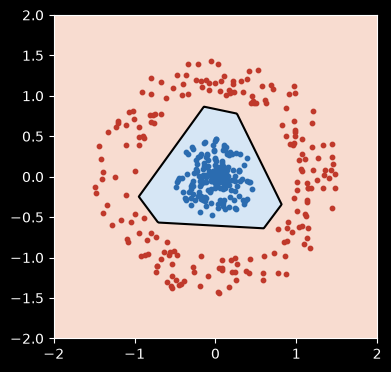

In [74]:
report(neural_network)
plot_boundary(neural_network)

- 另外一种写法

In [75]:
loss_fn = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(network.parameters(), lr=1.0)
for _ in range(3000):
    optimizer.zero_grad()
    # output = neural_network(x_train, w1, w2, b1, b2)
    output = network(x_train).squeeze()
    loss = loss_fn(output, y_train)
    if _ in [0, 100, 500, 2000, 3000]:
        print(f"当前轮次{_}的损失是{loss.item():.3f}")

    loss.backward()
    optimizer.step()


当前轮次0的损失是0.669
当前轮次100的损失是0.011
当前轮次500的损失是0.002
当前轮次2000的损失是0.000


训练集准确率：50.5%
验证集准确率：53.8%
测试集准确率：50.0%


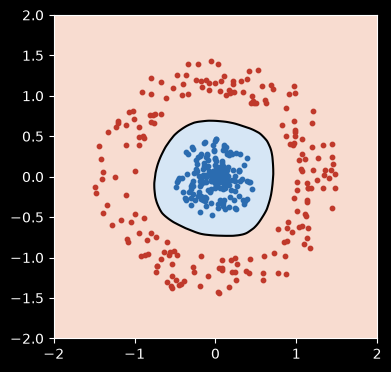

In [76]:
report(network)
plot_boundary(network)